Dataset CIFAR - 10 dataset
All the images are RGB images

total images = 60000
one image is 32*32 size
classes = 10

train dataset = 50000
test dataset = 10000


In [83]:
import ssl   # ssl certificate error fix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision   # Computer vision library
import torchvision.transforms as transforms   # image manipulate library (resize, crop, etc.)
from torch.utils.data import DataLoader, Subset  # DataLoader batch wise data loading

ssl._create_default_https_context = ssl._create_unverified_context

torch.manual_seed(42) # First random assign weights and bias

Check device has CPU or GPU or MPS (Apple silicon chip)

In [84]:
device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)

print(f"Using device: {device}\n")

Using device: cpu



In [85]:
# Hyperparameters

batch_size = 128
learning_rate = 0.001
weight_decay = 1e-4
epochs = 20
validation_size = 5000  # Validation dataset get from training dataset
checkpoint_path = "best_cifar10_model.pt"

In [86]:
# 4. CIFAR-10 normalization values

# this is same for Scikit-Learn StandardScaler but pytorch directly not have it so we have to write it ourselves

# Z Score value = (value - mean) / std

mean = [0.4914, 0.4822, 0.4465] # R, G, B
std = [0.2470, 0.2435, 0.2616] # R, G, B

# Data augmentation / image augmentation
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),  # image crop each epoch because it is overfitting problem so we have to crop it to avoid overfitting problem 
    transforms.RandomHorizontalFlip(), # image horizontal flip each epoch because it is overfitting problem so we have to horizontal flip it to avoid overfitting problem , 50% chance horizontal flip 
    transforms.ToTensor(), # (0, 255) to (0, 1) ,  [32,32,3] to [1,3,32,32] ,  float32
    transforms.Normalize(mean, std) # Standardization
])


# Validation / test transform
eval_transform = transforms.Compose([
    transforms.ToTensor(), # (0, 255) to (0, 1) ,  [32,32,3] to [1,3,32,32] ,  float32
    transforms.Normalize(mean, std) # Standardization
])


print(train_transform)
print(type(train_transform))
print(eval_transform)
print(type(eval_transform))


Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
)
<class 'torchvision.transforms.transforms.Compose'>
Compose(
    ToTensor()
    Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
)
<class 'torchvision.transforms.transforms.Compose'>


In [87]:
full_train_dataset_train = torchvision.datasets.CIFAR10(

    root="./data",
    train = True,
    transform = train_transform,
    download = True

)

full_train_dataset_eval = torchvision.datasets.CIFAR10(
    root = "./data",
    train = True,
    transform = eval_transform,
    download = False
) 

test_dataset = torchvision.datasets.CIFAR10(
    root = "./data",
    train = False,
    transform = eval_transform,
    download = True
)

print(type(full_train_dataset_train))
print(full_train_dataset_train)

<class 'torchvision.datasets.cifar.CIFAR10'>
Dataset CIFAR10
    Number of datapoints: 50000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               RandomCrop(size=(32, 32), padding=4)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
           )


In [88]:
first_item = full_train_dataset_train[0] # [image, label] this output show label 6 it's frog classification
print(type(first_item))

print(first_item)

image_tensor , label = first_item

print(f"The Label is : {label}")
print(f"The Tensor Shape is : {image_tensor.shape}\n")

<class 'tuple'>
(tensor([[[-1.9895, -0.2589, -0.0843,  ..., -0.6717, -1.2115, -1.7354],
         [-1.9895, -0.4971, -0.0684,  ..., -0.3065, -0.6082, -1.3862],
         [-1.9895, -0.9257, -0.7987,  ...,  0.0269, -0.3700, -1.0527],
         ...,
         [-1.9895, -0.0366,  0.4079,  ...,  0.9954,  0.8525,  0.6778],
         [-1.9895, -1.9895, -1.9895,  ..., -1.9895, -1.9895, -1.9895],
         [-1.9895, -1.9895, -1.9895,  ..., -1.9895, -1.9895, -1.9895]],

        [[-1.9803, -0.8046, -0.6275,  ..., -1.1750, -1.5455, -1.8676],
         [-1.9803, -0.9818, -0.6114,  ..., -0.9657, -1.1106, -1.6582],
         [-1.9803, -1.3039, -1.2234,  ..., -0.7080, -0.9335, -1.4649],
         ...,
         [-1.9803, -0.4986, -0.0799,  ...,  0.4194,  0.3066,  0.0973],
         [-1.9803, -1.9803, -1.9803,  ..., -1.9803, -1.9803, -1.9803],
         [-1.9803, -1.9803, -1.9803,  ..., -1.9803, -1.9803, -1.9803]],

        [[-1.7068, -1.0772, -0.9573,  ..., -1.3620, -1.5869, -1.7068],
         [-1.7068, -1.1821, 

In [89]:
first_test = test_dataset[0]

print(first_test)

image_tensor , label = first_test

print(f"The Label is : {label}")
print(f"The Tensor Shape is : {image_tensor.shape}\n")

(tensor([[[ 0.5191,  0.5349,  0.6302,  ...,  0.1856,  0.0110, -0.1478],
         [ 0.4238,  0.4079,  0.5349,  ...,  0.1698, -0.0049, -0.1001],
         [ 0.4079,  0.4079,  0.5191,  ...,  0.2174,  0.0745, -0.0843],
         ...,
         [-0.9099, -1.3226, -1.4973,  ..., -1.3862, -1.7831, -1.3544],
         [-1.0210, -1.2115, -1.4338,  ..., -1.5767, -1.5290, -1.6719],
         [-1.1321, -1.1004, -1.2750,  ..., -1.6084, -1.4497, -1.6561]],

        [[-0.1765, -0.1926, -0.1121,  ..., -0.4503, -0.5147, -0.6114],
         [-0.1765, -0.2087, -0.1443,  ..., -0.4503, -0.5147, -0.5630],
         [-0.2087, -0.2248, -0.1926,  ..., -0.4020, -0.4503, -0.5469],
         ...,
         [ 0.0167, -0.3698, -0.5630,  ..., -0.4181, -0.9496, -0.6114],
         [-0.1121, -0.3376, -0.6114,  ..., -0.6597, -0.6597, -0.9496],
         [-0.2571, -0.2893, -0.5469,  ..., -0.7402, -0.6275, -0.9013]],

        [[-0.9723, -1.0022, -0.9423,  ..., -1.1671, -1.1671, -1.2121],
         [-0.9423, -1.1072, -1.0322,  ..., -

Train / Validation Split

In [90]:
num_train = len(full_train_dataset_train)

indices = torch.randperm(num_train, generator=torch.Generator().manual_seed(42)).tolist()

print(num_train)
print(indices)

50000
[37542, 44491, 216, 43688, 41558, 32245, 27206, 10863, 2190, 31849, 25408, 33504, 27102, 21934, 40181, 47682, 45747, 17004, 43777, 7433, 45129, 37684, 14817, 38215, 30883, 19763, 14041, 46578, 19871, 39339, 39292, 8205, 47307, 15337, 45371, 20844, 26455, 25747, 21000, 49417, 42186, 49238, 25283, 78, 6899, 15568, 11143, 35952, 37965, 33436, 30770, 9583, 35210, 4856, 8020, 44859, 4191, 19421, 34688, 29312, 20326, 17740, 4894, 20621, 2614, 46726, 19045, 5668, 6159, 47718, 7907, 5294, 42872, 24855, 20370, 21209, 32223, 43179, 44262, 38506, 40214, 16895, 12328, 45173, 46138, 13520, 30459, 20165, 11227, 43731, 42697, 17911, 6857, 33366, 32393, 2860, 19849, 43759, 3139, 6468, 29670, 7952, 25577, 16817, 27801, 28896, 19279, 5004, 19713, 33819, 49625, 2477, 25719, 37877, 13626, 23084, 1540, 35115, 38527, 48710, 22399, 1907, 35869, 26348, 49760, 43079, 14963, 46994, 1499, 36242, 38017, 21469, 17152, 28914, 18402, 37833, 15968, 42387, 28214, 15104, 29119, 49456, 8253, 37588, 35879, 48267, 3

In [91]:
val_indices = indices[:validation_size]
train_indices = indices[validation_size:]

print(len(val_indices))
print(val_indices)
print(len(train_indices))
print(train_indices)

5000
[37542, 44491, 216, 43688, 41558, 32245, 27206, 10863, 2190, 31849, 25408, 33504, 27102, 21934, 40181, 47682, 45747, 17004, 43777, 7433, 45129, 37684, 14817, 38215, 30883, 19763, 14041, 46578, 19871, 39339, 39292, 8205, 47307, 15337, 45371, 20844, 26455, 25747, 21000, 49417, 42186, 49238, 25283, 78, 6899, 15568, 11143, 35952, 37965, 33436, 30770, 9583, 35210, 4856, 8020, 44859, 4191, 19421, 34688, 29312, 20326, 17740, 4894, 20621, 2614, 46726, 19045, 5668, 6159, 47718, 7907, 5294, 42872, 24855, 20370, 21209, 32223, 43179, 44262, 38506, 40214, 16895, 12328, 45173, 46138, 13520, 30459, 20165, 11227, 43731, 42697, 17911, 6857, 33366, 32393, 2860, 19849, 43759, 3139, 6468, 29670, 7952, 25577, 16817, 27801, 28896, 19279, 5004, 19713, 33819, 49625, 2477, 25719, 37877, 13626, 23084, 1540, 35115, 38527, 48710, 22399, 1907, 35869, 26348, 49760, 43079, 14963, 46994, 1499, 36242, 38017, 21469, 17152, 28914, 18402, 37833, 15968, 42387, 28214, 15104, 29119, 49456, 8253, 37588, 35879, 48267, 37

In [92]:
train_dataset = Subset(full_train_dataset_train, train_indices)
val_dataset = Subset(full_train_dataset_eval, val_indices)

print(type(train_dataset))
print(train_dataset)
print(train_dataset[0])
print(train_dataset[0][0].shape)

print(len(val_dataset))
print(len(train_dataset))

<class 'torch.utils.data.dataset.Subset'>
(tensor([[[-1.9895, -1.9895, -1.9895,  ..., -0.3065, -0.3542, -0.3065],
         [-1.9895, -1.9895, -1.9895,  ..., -0.4018, -0.4018, -0.3383],
         [-1.9895, -1.9895, -1.9895,  ..., -0.3383, -0.3383, -0.2907],
         ...,
         [-1.9895, -1.9895, -1.9895,  ..., -0.4494, -0.4812, -0.6082],
         [-1.9895, -1.9895, -1.9895,  ..., -0.2430, -0.3383, -0.4494],
         [-1.9895, -1.9895, -1.9895,  ..., -0.3224, -0.3700, -0.3700]],

        [[-1.9803, -1.9803, -1.9803,  ..., -0.5469, -0.5953, -0.5469],
         [-1.9803, -1.9803, -1.9803,  ..., -0.6436, -0.6436, -0.5630],
         [-1.9803, -1.9803, -1.9803,  ..., -0.5792, -0.5792, -0.5308],
         ...,
         [-1.9803, -1.9803, -1.9803,  ..., -0.7402, -0.7563, -0.8368],
         [-1.9803, -1.9803, -1.9803,  ..., -0.5469, -0.6275, -0.6919],
         [-1.9803, -1.9803, -1.9803,  ..., -0.5953, -0.6436, -0.6436]],

        [[-1.7068, -1.7068, -1.7068,  ..., -0.4926, -0.5375, -0.4626],
  

In [93]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(train_loader)

for i in train_loader:
    
    print(type(i))
    print(i)
    print("*"*50)
    print(i[0])
    print(i[0].shape)
    print(i[1])
    break

<class 'list'>
[tensor([[[[-1.9895, -1.9895, -1.9895,  ..., -1.9895, -1.9895, -1.9895],
          [-1.9895, -1.9895, -1.9895,  ..., -1.9895, -1.9895, -1.9895],
          [-1.9895, -1.9895, -1.9895,  ..., -1.9895, -1.9895, -1.9895],
          ...,
          [-1.8625, -1.9418, -0.6399,  ..., -1.9895, -1.9895, -1.9895],
          [-1.8307, -1.7831, -0.1160,  ..., -1.9895, -1.9895, -1.9895],
          [-1.7672, -1.3703, -0.0843,  ..., -1.9895, -1.9895, -1.9895]],

         [[-1.9803, -1.9803, -1.9803,  ..., -1.9803, -1.9803, -1.9803],
          [-1.9803, -1.9803, -1.9803,  ..., -1.9803, -1.9803, -1.9803],
          [-1.9803, -1.9803, -1.9803,  ..., -1.9803, -1.9803, -1.9803],
          ...,
          [-1.8192, -1.9642, -0.7724,  ..., -1.9803, -1.9803, -1.9803],
          [-1.8192, -1.8031, -0.2248,  ..., -1.9803, -1.9803, -1.9803],
          [-1.8514, -1.4488, -0.1765,  ..., -1.9803, -1.9803, -1.9803]],

         [[-1.7068, -1.7068, -1.7068,  ..., -1.7068, -1.7068, -1.7068],
          [-1.

Design Architecture

In [94]:
class SimpleCNN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=32,kernel_size=3,padding=1),  # input channel = 3 , output channel = 32
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64,out_channels=128,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=128*4*4,out_features=256),
            nn.ReLU(),
            nn.Linear(in_features=256,out_features=num_classes)

        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

 
model = SimpleCNN(num_classes=10).to(device)






In [95]:
print(list(model.parameters()))

[Parameter containing:
tensor([[[[ 2.0816e-02,  5.7019e-02, -8.8856e-02],
          [-5.3847e-02,  1.2997e-01,  1.5331e-02],
          [ 8.6830e-03, -4.7362e-02, -1.7428e-01]],

         [[-1.8095e-01, -9.1994e-02, -9.7827e-02],
          [ 5.9959e-02, -5.6024e-02, -7.5291e-02],
          [ 1.8349e-01,  6.7035e-02,  1.3720e-01]],

         [[-9.3168e-02, -7.8609e-02,  7.0733e-02],
          [-1.2822e-01, -1.2581e-01, -9.2953e-03],
          [-7.0391e-02, -1.4427e-01,  1.1415e-01]]],


        [[[ 1.5476e-01,  3.1220e-02, -3.3508e-02],
          [-1.7826e-01, -7.0098e-02,  4.8995e-02],
          [ 9.0746e-02, -2.4329e-02, -7.6086e-02]],

         [[ 1.0724e-01, -1.5327e-01,  1.2163e-01],
          [-7.4662e-02,  2.9455e-03, -3.8031e-02],
          [ 2.3332e-02, -5.8158e-02,  1.3994e-01]],

         [[-5.0032e-03,  1.5023e-01,  1.8504e-01],
          [-9.3760e-02, -1.4039e-01,  1.5440e-01],
          [ 1.5081e-01, -1.4694e-01, -1.4877e-02]]],


        [[[-1.8978e-01, -1.5754e-01,  3.717

In [96]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

In [97]:
# List for monitoring

train_loss = []
train_accuracies = []
val_loss = []
val_accuracies = []

best_val_accuracy = 0.0

In [98]:
def evaluate(model, data_loader):

    model.eval()
    running_loss = 0.0
    correct = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(data_loader.dataset)
    epoch_accuracy = 100*correct / len(data_loader.dataset)

    return epoch_loss, epoch_accuracy

In [99]:
# Training loop
print("Starting training ...\n")

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    train_correct = 0
    #count = 0

    for images, labels in train_loader:
        images, label = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, label)
        loss.backward()

        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    epoch_train_accuracy = 100*train_correct / len(train_loader.dataset)

    epoch_val_loss, epoch_val_accuracy = evaluate(model, val_loader)

    train_loss.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_loss.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)


    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

    if epoch_val_accuracy > best_val_accuracy:
        best_val_accuracy = epoch_val_accuracy
        torch.save(
            {
            "epoch":epoch+1,
            "model_state_dict":model.state_dict(),
            "optimizer_state_dict":optimizer.state_dict(),
            "val_accuracy":epoch_val_accuracy,
            "val_loss":epoch_val_loss,
            },
            checkpoint_path,
        )

        print(f"Best model saved at epoch {epoch+1}\n")



Starting training ...

Epoch [1/20] | Train Loss: 1.6036 | Train Accuracy: 40.91% | Val Loss: 1.2548 | Val Accuracy: 55.12%
Best model saved at epoch 1

Epoch [2/20] | Train Loss: 1.2336 | Train Accuracy: 55.86% | Val Loss: 1.0376 | Val Accuracy: 63.58%
Best model saved at epoch 2

Epoch [3/20] | Train Loss: 1.0509 | Train Accuracy: 62.67% | Val Loss: 0.9203 | Val Accuracy: 67.48%
Best model saved at epoch 3

Epoch [4/20] | Train Loss: 0.9222 | Train Accuracy: 67.20% | Val Loss: 0.8155 | Val Accuracy: 72.06%
Best model saved at epoch 4

Epoch [5/20] | Train Loss: 0.8470 | Train Accuracy: 70.16% | Val Loss: 0.7758 | Val Accuracy: 73.18%
Best model saved at epoch 5

Epoch [6/20] | Train Loss: 0.7875 | Train Accuracy: 72.20% | Val Loss: 0.7239 | Val Accuracy: 74.44%
Best model saved at epoch 6

Epoch [7/20] | Train Loss: 0.7468 | Train Accuracy: 73.74% | Val Loss: 0.7128 | Val Accuracy: 74.84%
Best model saved at epoch 7

Epoch [8/20] | Train Loss: 0.7095 | Train Accuracy: 75.02% | Val Lo

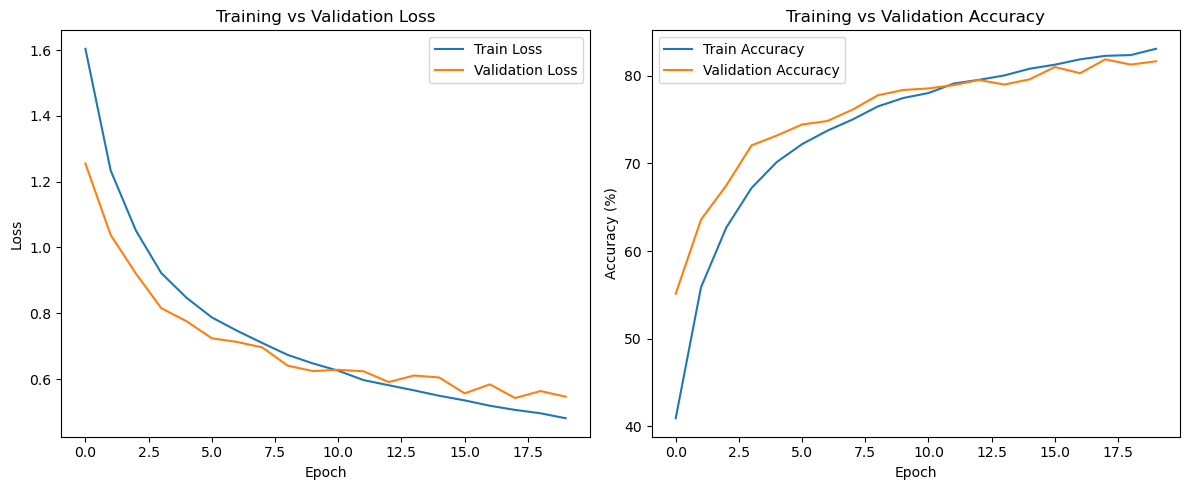

In [100]:
# 12. Plot graphs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [101]:
checkpoint = torch.load(checkpoint_path, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])

print(f"\nLoaded best model from epoch {checkpoint['epoch']}")
print(f"Best Validation Accuracy: {checkpoint['val_accuracy']:.2f}%")
print(f"Best Validation Loss : {checkpoint['val_loss']:.4f}\n")


Loaded best model from epoch 18
Best Validation Accuracy: 81.88%
Best Validation Loss : 0.5424



In [102]:
test_loss, test_accuracy = evaluate(model, test_loader)

print("\nStarting final testing")
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy:.2f}%\n")


Starting final testing
Final Test Loss: 0.5797
Final Test Accuracy: 80.57%



In [ ]:
# 15. Predict on a custom image

from PIL import Image   # Use Pillow library

# 1. Create a dictionary to translate math indices back to English words
cifar10_classes = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
                   'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# This function takes the path to a custom image, processes it to match the CIFAR-10 format,
# and then uses the trained model to predict which of the 10 classes it belongs to.
# It also prints out the confidence level of the prediction.
def predict_custom_image(image_path, model, device):
    # 2. The Translator: Force the internet image to follow CIFAR-10 rules
    inference_transform = transforms.Compose([
        transforms.Resize((32, 32)), # Crush the image down to 32x32
        transforms.ToTensor(),       # Convert to math matrix
        transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], # Apply exact same standardization
                             std=[0.2023, 0.1994, 0.2010])
    ])

    # 3. Open the image and force it to be standard RGB
    img = Image.open(image_path).convert('RGB')
    print(type(img))  # <class 'PIL.JpegImagePlugin.JpegImageFile'>
    print(img)

    # 4. Apply the translator (Shape becomes [3, 32, 32])
    img_tensor = inference_transform(img)

    print(f'image tensor: {img_tensor}')
    print(f'image tensor shape: {img_tensor.shape}')  # torch.Size([3, 32, 32])

    # 5. Add a fake "Batch" dimension so PyTorch doesn't crash (Shape becomes [1, 3, 32, 32])
    img_tensor = img_tensor.unsqueeze(0).to(device)
    print(f'image tensor with batch dimension: {img_tensor}')
    print(f'image tensor shape with batch dimension: {img_tensor.shape}')  # torch.Size([1, 3, 32, 32])

    # 6. Use evaluation mode, and do not record gradients for this prediction
    model.eval()
    with torch.no_grad():
        # Get raw logits
        logits = model(img_tensor)

        print(f'logits: {logits}')
        print(f'logits shape: {logits.shape}')  # torch.Size([1, 10])

        # Turn logits into human-readable percentages (since we are printing it to the screen!)
        probabilities = torch.nn.functional.softmax(logits, dim=1)[0]
        print(f'probabilities: {probabilities}')

        # Find the highest percentage and its index position
        confidence, winning_index = torch.max(probabilities, dim=0)

    # Translate the winning index back to English
    predicted_label = cifar10_classes[winning_index.item()]

    print(f"The model thinks this is a: {predicted_label}")
    print(f"Confidence: {confidence.item() * 100:.2f}%")

# --- How to use it ---
predict_custom_image("./images/image_18.png", model, device)

<class 'PIL.Image.Image'>
<PIL.Image.Image image mode=RGB size=148x148 at 0x1E01E52C1A0>
image tensor: tensor([[[2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947],
         [2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947],
         [2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947],
         ...,
         [2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947],
         [2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947],
         [2.4947, 2.4947, 2.4947,  ..., 2.4947, 2.4947, 2.4947]],

        [[2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771],
         [2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771],
         [2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771],
         ...,
         [2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771],
         [2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771],
         [2.5771, 2.5771, 2.5771,  ..., 2.5771, 2.5771, 2.5771]],

        [[2.7342, 2.7342, 2.7342,  ..., 2.7342, 2.7342, 2.7342],
         [2.7342, 2.